# 01 — Synthetic training data

No labelled humanitarian convoy dataset exists, so both models are trained on **synthetic, domain-informed** data
(section 4 of the project summary). This notebook:

1. Defines the shared feature spec (`artifacts/feature_spec.json`) used by every later notebook.
2. Generates Model 1 rows: vehicle + weather + route features → continuous `risk_score` (0–1).
3. Generates Model 2 rows: disruption + route alternatives → one of four actions, labelled by a transparent expert policy.

> State clearly in the pitch that this is synthetic data and that real deployment would need operational validation.

In [1]:
from pathlib import Path

# Works both when Jupyter is started in the repo root and inside notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
ART = ROOT / "artifacts"
DATA.mkdir(exist_ok=True)
ART.mkdir(exist_ok=True)

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)
N_MODEL1 = 20_000
N_MODEL2 = 20_000

## Shared feature spec

In [2]:
M1_FEATURES = [
    "speed_kmh", "fuel_level_pct", "rainfall_mm_per_hr", "wind_speed_kmh", "flood_risk",
    "traffic_congestion", "distance_to_hazard_km", "route_delay_minutes", "road_closure_nearby",
]
M2_CATEGORICAL = ["disruption_type"]
M2_NUMERIC = [
    "disruption_severity", "current_route_risk", "alternative_route_available", "alternative_route_risk",
    "extra_detour_minutes", "fuel_level_pct", "cargo_priority", "estimated_hazard_duration_min",
    "backup_hub_available",
]
DISRUPTION_TYPES = ["FLOOD", "SEVERE_WEATHER", "ROAD_CLOSURE", "TRAFFIC_INCIDENT"]
ACTIONS = ["CONTINUE_MONITORING", "HOLD_POSITION", "REROUTE", "DIVERT_TO_BACKUP_HUB"]

# Operational threshold for invoking Model 2. A prototype choice, not a scientific standard.
RISK_THRESHOLD = 0.75

# "Nothing is wrong" reference values, used later to attribute a risk score to individual features.
CALM_REFERENCE = {
    "speed_kmh": 60.0, "fuel_level_pct": 70.0, "rainfall_mm_per_hr": 0.0, "wind_speed_kmh": 10.0,
    "flood_risk": 0.02, "traffic_congestion": 0.2, "distance_to_hazard_km": 50.0,
    "route_delay_minutes": 0.0, "road_closure_nearby": 0,
}

spec = {
    "model1_features": M1_FEATURES,
    "model2_categorical": M2_CATEGORICAL,
    "model2_numeric": M2_NUMERIC,
    "disruption_types": DISRUPTION_TYPES,
    "actions": ACTIONS,
    "risk_threshold": RISK_THRESHOLD,
    "calm_reference": CALM_REFERENCE,
    "seed": SEED,
}
(ART / "feature_spec.json").write_text(json.dumps(spec, indent=2))
print("Wrote", ART / "feature_spec.json")

Wrote /home/george/ReliefZ/artifacts/feature_spec.json


## Model 1 data — route risk

Each row is either a *calm* or a *hazard* scenario (35%), so the full 0–1 risk range is covered.
The target is a logistic combination of the hazard signals plus Gaussian noise. These weights are the
"domain knowledge" of the prototype — tune them, and be ready to explain them.

In [3]:
def mix(is_hazard, calm, hazard):
    return np.where(is_hazard, hazard, calm)


def risk_formula(df):
    proximity = np.exp(-df["distance_to_hazard_km"] / 2.0)          # 1 at the hazard, ~0 beyond 8 km
    rain = np.clip(df["rainfall_mm_per_hr"] / 50.0, 0, 1)
    wind = np.clip(df["wind_speed_kmh"] / 100.0, 0, 1)
    delay = np.clip(df["route_delay_minutes"] / 120.0, 0, 1)
    z = (
        -4.0
        + 3.5 * df["flood_risk"] * (0.4 + 0.6 * proximity)
        + 1.5 * rain
        + 0.8 * wind
        + 1.2 * df["traffic_congestion"]
        + 1.0 * delay
        + 1.5 * df["road_closure_nearby"]
        + 1.5 * proximity
        + 0.6 * (df["speed_kmh"] < 15)
        + 0.5 * (df["fuel_level_pct"] < 20)
    )
    return 1.0 / (1.0 + np.exp(-z))


n = N_MODEL1
h = rng.random(n) < 0.35
m1 = pd.DataFrame({
    "speed_kmh": np.clip(mix(h, rng.normal(65, 12, n), rng.normal(35, 18, n)), 0, 110),
    "fuel_level_pct": rng.uniform(5, 100, n),
    "rainfall_mm_per_hr": mix(h, rng.gamma(1.2, 3, n), rng.gamma(3, 10, n)),
    "wind_speed_kmh": np.clip(mix(h, rng.normal(15, 8, n), rng.normal(55, 20, n)), 0, None),
    "flood_risk": mix(h, rng.beta(1, 8, n), rng.beta(4, 2, n)),
    "traffic_congestion": mix(h, rng.beta(2, 4, n), rng.beta(4, 3, n)),
    "distance_to_hazard_km": np.clip(mix(h, rng.uniform(10, 60, n), rng.exponential(4, n)), 0, 60),
    "route_delay_minutes": mix(h, rng.exponential(5, n), rng.exponential(35, n)),
    "road_closure_nearby": mix(h, rng.random(n) < 0.03, rng.random(n) < 0.35).astype(int),
})
m1["risk_score"] = np.clip(risk_formula(m1) + rng.normal(0, 0.03, n), 0, 1)

m1.to_csv(DATA / "model1_training.csv", index=False)
m1.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
speed_kmh,20000.0,54.41,20.39,0.0,41.88,58.17,69.02,110.00
fuel_level_pct,20000.0,52.72,27.28,5.0,29.26,52.94,76.11,100.00
rainfall_mm_per_hr,20000.0,13.02,16.71,0.0,1.91,5.15,19.07,141.19
wind_speed_kmh,20000.0,29.31,23.26,0.0,12.54,20.49,44.12,124.70
flood_risk,20000.0,0.31,0.30,0.0,0.06,0.17,0.57,1.00
traffic_congestion,20000.0,0.42,0.21,0.0,0.25,0.40,0.58,0.98
distance_to_hazard_km,20000.0,24.23,19.05,0.0,4.92,21.79,40.94,60.00
route_delay_minutes,20000.0,15.47,25.12,0.0,2.17,5.92,15.97,384.25
road_closure_nearby,20000.0,0.14,0.35,0.0,0.00,0.00,0.00,1.00
risk_score,20000.0,0.26,0.32,0.0,0.04,0.07,0.50,1.00


## Model 2 data — operational response

Labels come from an explicit expert policy (below) with 3% label noise. Model 2 therefore *learns this policy*;
its value in the demo is a fast, probabilistic, auditable recommender that could later be retrained on real
dispatcher decisions (the "feedback learning" stretch goal).

In [4]:
DURATION_SCALE = {"FLOOD": 80, "SEVERE_WEATHER": 60, "ROAD_CLOSURE": 90, "TRAFFIC_INCIDENT": 20}

n = N_MODEL2
dtype = rng.choice(DISRUPTION_TYPES, n)
has_alt = (rng.random(n) < 0.7).astype(int)
in_alert = rng.random(n) < 0.7
m2 = pd.DataFrame({
    "disruption_type": dtype,
    "disruption_severity": rng.beta(2, 2, n),
    "current_route_risk": np.where(in_alert, rng.uniform(RISK_THRESHOLD, 1.0, n), rng.uniform(0, RISK_THRESHOLD, n)),
    "alternative_route_available": has_alt,
    "alternative_route_risk": np.where(has_alt == 1, rng.uniform(0.05, 0.9, n), 1.0),
    "extra_detour_minutes": np.where(has_alt == 1, rng.gamma(2, 15, n), 0.0),
    "fuel_level_pct": rng.uniform(5, 100, n),
    "cargo_priority": rng.integers(1, 6, n),
    "estimated_hazard_duration_min": rng.gamma(2.5, 1, n) * np.array([DURATION_SCALE[t] for t in dtype]),
    "backup_hub_available": (rng.random(n) < 0.6).astype(int),
})


def expert_policy(r):
    if r.current_route_risk < RISK_THRESHOLD:
        return "CONTINUE_MONITORING"
    fuel_needed = 10 + 0.25 * r.extra_detour_minutes          # % of tank, rough planning buffer
    viable_alt = (
        r.alternative_route_available == 1
        and r.alternative_route_risk < RISK_THRESHOLD
        and r.alternative_route_risk <= r.current_route_risk - 0.25
        and r.fuel_level_pct >= fuel_needed
    )
    # Reroute when it beats waiting, or when cargo is urgent enough that waiting is not acceptable
    if viable_alt and (r.extra_detour_minutes < r.estimated_hazard_duration_min or r.cargo_priority >= 4):
        return "REROUTE"
    if r.backup_hub_available == 1 and (r.estimated_hazard_duration_min > 120 or r.fuel_level_pct < 15):
        return "DIVERT_TO_BACKUP_HUB"
    return "HOLD_POSITION"


m2["action"] = m2.apply(expert_policy, axis=1)
noise = rng.random(n) < 0.03
m2.loc[noise, "action"] = rng.choice(ACTIONS, noise.sum())

m2.to_csv(DATA / "model2_training.csv", index=False)
m2["action"].value_counts()

action
CONTINUE_MONITORING     6005
HOLD_POSITION           5586
REROUTE                 5399
DIVERT_TO_BACKUP_HUB    3010
Name: count, dtype: int64

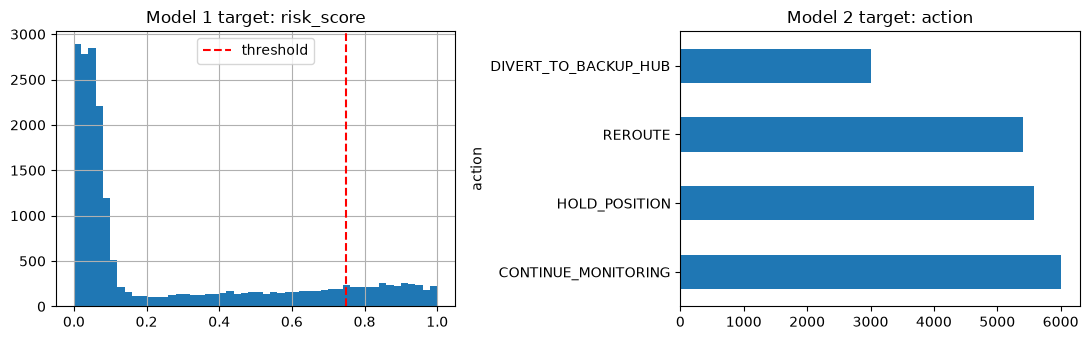

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
m1["risk_score"].hist(bins=50, ax=axes[0])
axes[0].axvline(RISK_THRESHOLD, color="red", ls="--", label="threshold")
axes[0].set_title("Model 1 target: risk_score")
axes[0].legend()
m2["action"].value_counts().plot.barh(ax=axes[1], title="Model 2 target: action")
plt.tight_layout()